<a href="https://colab.research.google.com/github/GLzanetti/Projetos-de-Machine-Learning/blob/main/Aula6_MachineLearning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Aula 6 - Machine Learning, prever o campeão da copa do mundo

## Previsão Científica e Simulação da Copa do Mundo 2026
Este projeto utiliza técnicas de Inteligência Artificial e Modelagem Estatística para simular a realização da Copa do Mundo de 2026. Com base no histórico de confrontos internacionais de futebol masculinos desde 1872, avaliamos o desempenho relativo de cada seleção e estimamos as probabilidades de cada partida do torneio, desde a fase de grupos até a grande final.

### 📋 Objetivo do Modelo
O principal objetivo é aplicar algoritmos de Machine Learning para prever a probabilidade dos resultados de jogos de futebol (Vitória, Empate ou Derrota) em campo neutro e, através de simulações de Monte Carlo (1000 repetições de todo o campeonato), determinar estatisticamente as chances de cada país se consagrar campeão mundial.

### 🛠️ Detalhes da Implementação
O pipeline do projeto foi desenvolvido com as seguintes etapas chaves:
1. **Modelagem de Força (Rating Elo):** Implementamos um algoritmo de Rating Elo adaptado para futebol para calcular a força dinâmica de cada seleção com base no histórico de jogos desde 2010.
2. **Preparação dos Dados:** Calculamos a diferença de pontuação Elo entre os adversários e o fator de mando de campo para servir como atributos de entrada do modelo.
3. **Treinamento do Classificador (K-Neighbors Classifier):** Treinamos um modelo KNN para estimar a probabilidade de vitória, empate ou derrota com base em partidas historicamente semelhantes.
4. **Divisão de Grupos e Chaveamento:** Selecionamos as 48 seleções participantes da Copa de 2026, dividimos as equipes em potes de força, sorteamos os grupos e recriamos as regras oficiais do torneio.
5. **Simulação de Monte Carlo:** Simulamos a Copa do Mundo de 2026 por 1000 vezes para obter a distribuição probabilística do campeão e apresentamos os resultados finais em forma de gráfico de barras.

In [ ]:
# Importação de bibliotecas essenciais para manipulação de dados, modelagem matemática e plotagem de gráficos
import kagglehub
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Ferramentas auxiliares de coleções, combinações e Machine Learning (algoritmo KNN e padronização)
from collections import defaultdict
from itertools import combinations
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler

In [ ]:
# Inicializa o gerador de números aleatórios com uma semente fixa para reprodutibilidade
rng = np.random.default_rng(42)

# Baixa o histórico de partidas de futebol internacional diretamente do Kaggle
arquivo = kagglehub.dataset_download("martj42/international-football-results-from-1872-to-2017", path="results.csv")

# Carrega os jogos, converte as datas e filtra para manter apenas partidas realizadas a partir de 2010
jogos = pd.read_csv(arquivo)
jogos["date"] = pd.to_datetime(jogos["date"])
jogos = jogos[jogos["date"]>="2010-01-01"].sort_values("date")

100%|██████████| 3.59M/3.59M [00:00<00:00, 8.63MB/s]


In [ ]:
# Inicializa o dicionário de Rating Elo com um valor padrão de 1500 pontos para cada seleção
elo = defaultdict(lambda: 1500)
dados = []

# Loop que percorre linha a linha o histórico de jogos para calcular as variações de Elo ao longo do tempo
for indice, jogo in jogos.iterrows():
    casa = jogo["home_team"]
    fora = jogo["away_team"]
    mando = 0 if jogo["neutral"] else 1 # Define se há vantagem de jogar em casa (mando)

    # Determina o resultado real da partida sob a perspectiva do time da casa
    if jogo["home_score"] > jogo["away_score"]:
        resultado, real = "Casa", 1
    elif jogo["home_score"] < jogo["away_score"]:
        resultado, real = "Fora", 0
    else:
        resultado, real = "Empate", 0.5

    # Armazena a diferença de Elo pré-jogo e o mando de campo para o treinamento do classificador
    dados.append([elo[casa]-elo[fora], mando, resultado])

    # Cálculo de probabilidade esperada (fórmula clássica do sistema de Rating Elo)
    esperado = 1 / (1 + 10 ** (elo[fora]-elo[casa])/400)
    # Ajusta a pontuação Elo das seleções baseando-se no fator de impacto K = 30
    ajuste = 30 * (real - esperado)
    elo[casa] += ajuste
    elo[fora] -= ajuste

# Transforma a lista de dados histórica estruturada em um DataFrame do Pandas
base = pd.DataFrame(dados, columns=["dif_elo", "mando", "resultado"])
base.head()

,dif_elo,mando,resultado
0,0.0,0,Casa
1,0.0,1,Empate
2,0.0,0,Casa
3,0.0,1,Fora
4,0.0,0,Empate


In [ ]:
# Divisão das variáveis explicativas (x) e da variável alvo (y)
x = base[["dif_elo", "mando"]]
y = base[["resultado"]]

# Separação teórica de treino e teste (75% para treino, 25% para teste) utilizando escala de dados
corte = int(len(base) * 0.75)
escala = StandardScaler()

x_treino = escala.fit_transform(x[:corte])
y_treino = y[:corte]
x_teste = escala.transform(x[corte:])
y_teste = y[corte:]

# Instancia e treina o classificador KNN configurado com 101 vizinhos mais próximos
modelo = KNeighborsClassifier(n_neighbors=101)
modelo.fit(escala.fit_transform(x), y)

/usr/local/lib/python3.13/dist-packages/sklearn/neighbors/_classification.py:239: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return self._fit(X, y)


KNeighborsClassifier(n_neighbors=101)

In [ ]:
# Baixa o conjunto de dados de desempenho dos jogadores da Copa de 2026 para obter as seleções participantes
arquivo = kagglehub.dataset_download(
    "rauffauzanrambe/fifa-world-cup-2026-player-performance-dataset",
    path="fifa_world_cup_2026_player_performance.csv"
)

jogadores = pd.read_csv(arquivo)
times = []

# Loop para identificar e listar apenas as 48 equipes oficiais que possuem um rating Elo calculado
for time in jogadores["team"].dropna().unique():
  if time in elo:
    times.append(time)
  else:
    print("Não foi encontrado o time: ", time)

print("Seleções", len(times))

100%|██████████| 16.4M/16.4M [00:00<00:00, 18.2MB/s]


Seleções 48


In [ ]:
# Ordena todas as seleções classificadas do maior ao menor Elo de forma decrescente
times = sorted(times, key=lambda time: elo[time], reverse=True)
# Separa os times em 4 potes de força com 12 equipes cada
potes = [times[0:12], times[12:24], times[24:36], times[36:48]]

# Embaralha os potes internamente para realizar um sorteio de grupos aleatório e imparcial
for pote in potes:
  rng.shuffle(pote)

grupos = {}
letras = "ABCDEFGHIJKL"

# Loop que monta os 12 grupos oficiais da Copa de 2026 (A até L) selecionando um time de cada pote por grupo
for i in range(12):
  grupos[letras[i]] = [potes[0][i], potes[1][i], potes[2][i], potes[3][i]]
  print(letras[i], "-> ", grupos[letras[i]])

A ->  ['Spain', 'Costa Rica', 'Ecuador', 'Iran']
B ->  ['Brazil', 'Austria', 'Qatar', 'Panama']
C ->  ['Italy', 'South Korea', 'Nigeria', 'Serbia']
D ->  ['Netherlands', 'Belgium', 'Australia', 'Peru']
E ->  ['Cameroon', 'Chile', 'Canada', 'Ghana']
F ->  ['England', 'Croatia', 'Senegal', 'Turkey']
G ->  ['United States', 'Colombia', 'Algeria', 'Scotland']
H ->  ['France', 'Uruguay', 'Egypt', 'Iraq']
I ->  ['Portugal', 'Saudi Arabia', 'Germany', 'Ukraine']
J ->  ['Morocco', 'Sweden', 'Mexico', 'Uzbekistan']
K ->  ['Argentina', 'South Africa', 'Switzerland', 'Jamaica']
L ->  ['Denmark', 'Japan', 'Poland', 'Tunisia']


In [ ]:
pares = [] # Lista para armazenar as tuplas contendo os confrontos possíveis
entradas = [] # Lista para armazenar a diferença de Elo de cada par

# Loops aninhados para criar todas as combinações de jogos em campo neutro (mando = 0) entre as seleções
for time_a in times:
  for time_b in times:
    if time_a != time_b:
      pares.append((time_a, time_b))
      entradas.append((elo[time_a]-elo[time_b], 0))

# Converte as entradas estruturadas e executa o modelo KNN para predizer a probabilidade de cada resultado
entradas = pd.DataFrame(entradas, columns=['dif_elo', 'mando'])
probabilidades = modelo.predict_proba(escala.transform(entradas))
chances = {}

# Loop que associa cada partida possível com suas respectivas probabilidades de Vitória, Empate e Derrota
for i in range(len(pares)):
  p = dict(zip(modelo.classes_, probabilidades[i]))
  chances[pares[i]] = [p['Casa'], p['Empate'], p['Fora']]

print(chances)

{('Spain', 'Argentina'): [np.float64(0.4752475247524752), np.float64(0.2871287128712871), np.float64(0.2376237623762376)], ('Spain', 'France'): [np.float64(0.5445544554455446), np.float64(0.22772277227722773), np.float64(0.22772277227722773)], ('Spain', 'England'): [np.float64(0.6138613861386139), np.float64(0.19801980198019803), np.float64(0.18811881188118812)], ('Spain', 'Portugal'): [np.float64(0.5742574257425742), np.float64(0.2871287128712871), np.float64(0.13861386138613863)], ('Spain', 'United States'): [np.float64(0.6534653465346535), np.float64(0.2079207920792079), np.float64(0.13861386138613863)], ('Spain', 'Italy'): [np.float64(0.6732673267326733), np.float64(0.2079207920792079), np.float64(0.1188118811881188)], ('Spain', 'Brazil'): [np.float64(0.6336633663366337), np.float64(0.24752475247524752), np.float64(0.1188118811881188)], ('Spain', 'Denmark'): [np.float64(0.6237623762376238), np.float64(0.25742574257425743), np.float64(0.1188118811881188)], ('Spain', 'Netherlands'): 

In [ ]:
# Função que simula uma partida individual com base nas probabilidades extraídas pelo KNN
def jogar(time_a, time_b):
    prob = chances[(time_a, time_b)]
    numero = rng.random() # Gera um decimal aleatório entre 0 e 1 para determinar o resultado do jogo

    if numero < prob[0]:
        return time_a
    elif numero < prob[0] + prob[1]:
        return None
    else:
        return time_b

# Função que simula as fases e regras da Copa do Mundo para apontar um campeão único
def simular_copa():
    pontos = defaultdict(int)
    classificados = []
    terceiros = []

    # FASE DE GRUPOS: Simula o sistema de pontos corridos dentro de cada um dos 12 grupos
    for grupo in grupos.values():
        for time_a, time_b in combinations(grupo, 2):
            vencedor = jogar(time_a, time_b)
            if vencedor is None:
                pontos[time_a] += 1
                pontos[time_b] += 1
            else:
                pontos[vencedor] += 3

        # Ordena a tabela do grupo aplicando um pequeno fator aleatório de desempate
        tabela = sorted(grupo, key=lambda time: pontos[time] + rng.random(), reverse=True)
        classificados += tabela[:2] # Avançam os dois primeiros de cada grupo
        terceiros.append(tabela[2])  # Vai para a repescagem dos melhores terceiros colocados

    # Seleciona os 8 melhores terceiros colocados gerais para completar as 32 equipes do mata-mata
    terceiros = sorted(terceiros, key=lambda time: pontos[time] + rng.random(), reverse=True)
    classificados += terceiros[:8]

    # MATA-MATA (Fase Eliminatória): Ordena os classificados e realiza confrontos eliminatórios até restar apenas o vencedor
    vivos = sorted(classificados, key=lambda time: pontos[time] + rng.random(), reverse=True)

    while len(vivos) > 1:
        vencedores = []
        for i in range(len(vivos) // 2):
            time_a = vivos[i]
            time_b = vivos[len(vivos) - 1 - i] # Emparelha o melhor com o pior
            prob = chances[(time_a, time_b)]
            chance_a = prob[0] / (prob[0] + prob[2]) # Normaliza a chance sem contar empates para garantir um vencedor

            if rng.random() < chance_a:
                vencedores.append(time_a)
            else:
                vencedores.append(time_b)
        vivos = vencedores

    return vivos[0]

# ===== 10. SIMULANDO 1000 COPAS =====
# Roda a simulação completa 1000 vezes para obter a amostragem de Monte Carlo e consolida as chances estatísticas
titulos = defaultdict(int)

for i in range(1000):
    campeao = simular_copa()
    titulos[campeao] += 1

ranking = pd.Series(titulos) / 1000 * 100
ranking = ranking.sort_values(ascending=False)

print("\nCHANCE DE SER CAMPEÃO (%)")
print(ranking.head(10).round(1))


CHANCE DE SER CAMPEÃO (%)
Spain            33.8
Argentina        12.1
France            9.5
England           8.2
Portugal          5.6
United States     4.9
Italy             3.8
Brazil            3.0
Netherlands       2.8
Morocco           2.4
dtype: float64


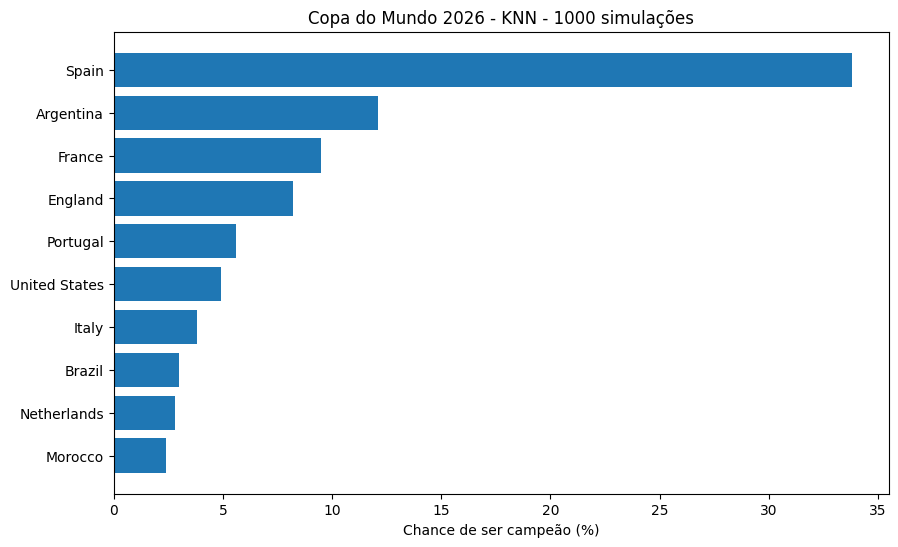

In [ ]:
# ===== 11. GRÁFICO =====
# Plota o ranking das 10 seleções com maiores probabilidades estimadas pelo algoritmo de simulação
top10 = ranking.head(10).sort_values()

plt.figure(figsize=(10, 6))
plt.barh(top10.index, top10.values)
plt.xlabel("Chance de ser campeão (%)")
plt.title("Copa do Mundo 2026 - KNN - 1000 simulações")
plt.show()

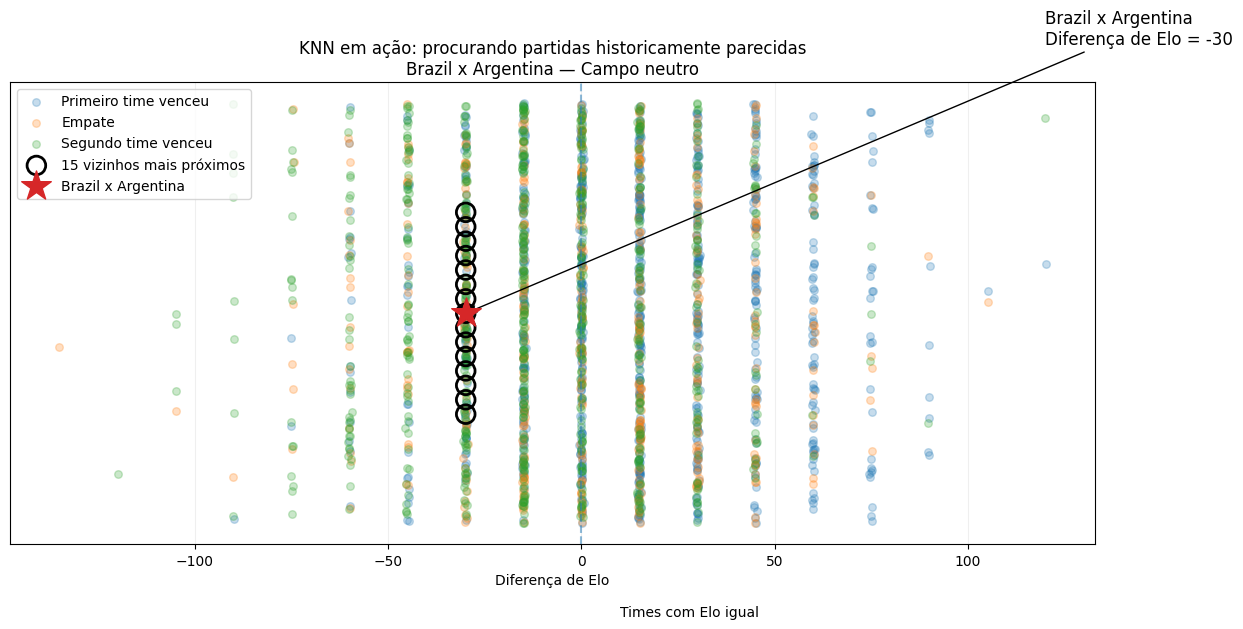

In [ ]:
# ============================================================
# VISUALIZAÇÃO DIDÁTICA DO KNN
# ============================================================

time_a = "Brazil"
time_b = "Argentina"

# Calcula a diferença de Elo histórica para a partida de teste selecionada
dif_elo = elo[time_a] - elo[time_b]

# Partida de teste específica estruturada no formato requerido pelo modelo
partida = pd.DataFrame(
    [[dif_elo, 0]],
    columns=["dif_elo", "mando"]
)

partida_escalada = escala.transform(partida)


# ------------------------------------------------------------
# PEGA OS 15 VIZINHOS MAIS PRÓXIMOS
# ------------------------------------------------------------
# Encontra as 15 amostras mais próximas da nossa partida de teste dentro do espaço do KNN
distancias, indices = modelo.kneighbors(
    partida_escalada,
    n_neighbors=15
)

vizinhos = base.iloc[indices[0]].copy()


# ------------------------------------------------------------
# PEGA SOMENTE JOGOS EM CAMPO NEUTRO
# ------------------------------------------------------------
neutros = base[base["mando"] == 0].copy()

# Seleciona uma amostra aleatória de partidas neutras históricas para manter a visualização limpa
neutros = neutros.sample(
    min(2000, len(neutros)),
    random_state=42
)

# Espalha os dados aleatoriamente no eixo vertical do gráfico para evitar sobreposição excessiva de pontos
rng_grafico = np.random.default_rng(42)

neutros["altura"] = rng_grafico.uniform(
    -0.25,
    0.25,
    len(neutros)
)


# ------------------------------------------------------------
# GRÁFICO
# ------------------------------------------------------------
# Plota os dados históricos dispersos separando por cores dependendo de quem venceu
plt.figure(figsize=(14, 6))

# Vitória do primeiro time
dados_casa = neutros[neutros["resultado"] == "Casa"]
plt.scatter(
    dados_casa["dif_elo"],
    dados_casa["altura"],
    alpha=0.25,
    s=30,
    label="Primeiro time venceu"
)

# Empate
dados_empate = neutros[neutros["resultado"] == "Empate"]
plt.scatter(
    dados_empate["dif_elo"],
    dados_empate["altura"],
    alpha=0.25,
    s=30,
    label="Empate"
)

# Vitória do segundo time
dados_fora = neutros[neutros["resultado"] == "Fora"]
plt.scatter(
    dados_fora["dif_elo"],
    dados_fora["altura"],
    alpha=0.25,
    s=30,
    label="Segundo time venceu"
)


# ------------------------------------------------------------
# VIZINHOS DO KNN
# ------------------------------------------------------------
# Realça graficamente no mapa onde se posicionam os 15 vizinhos mais próximos da nossa partida teste
alturas_vizinhos = np.linspace(
    -0.12,
    0.12,
    len(vizinhos)
)

plt.scatter(
    vizinhos["dif_elo"],
    alturas_vizinhos,
    s=180,
    facecolors="none",
    edgecolors="black",
    linewidths=2,
    label="15 vizinhos mais próximos"
)


# ------------------------------------------------------------
# BRASIL X ARGENTINA
# ------------------------------------------------------------
# Desenha uma estrela destacando a partida de teste selecionada no gráfico
plt.scatter(
    dif_elo,
    0,
    s=500,
    marker="*",
    label=f"{time_a} x {time_b}",
    zorder=10
)

plt.annotate(
    f"{time_a} x {time_b}\nDiferença de Elo = {dif_elo:.0f}",
    xy=(dif_elo, 0),
    xytext=(dif_elo + 150, 0.32),
    arrowprops=dict(arrowstyle="->"),
    fontsize=12
)

# Linha onde as equipes teriam exatamente a mesma força teórica
plt.axvline(
    0,
    linestyle="--",
    alpha=0.5
)

plt.text(
    10,
    -0.36,
    "Times com Elo igual",
    fontsize=10
)

plt.xlabel("Diferença de Elo")
plt.yticks([])

plt.title(
    "KNN em ação: procurando partidas historicamente parecidas\n"
    f"{time_a} x {time_b} — Campo neutro"
)

plt.legend()

plt.grid(
    axis="x",
    alpha=0.2
)

plt.show()